# Classificação de Imagens com timm

Este notebook utiliza a biblioteca `timm` (PyTorch Image Models) para baixar o modelo pré-treinado `mobilenetv3_small_100.lamb_in1k` e classificar as imagens contidas na pasta `imagens/` local.

In [1]:
import torch
import urllib.request
from PIL import Image
from pathlib import Path
import timm
from timm.data import resolve_data_config
from timm.data.transforms_factory import create_transform

c:\Users\felip\Desktop\recog_system\recog_system\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Inicializações do Modelo

Vamos invocar a função `create_model` usando o nome do modelo especificado. A biblioteca irá baixar e carregar os pesos na memória (`pretrained=True`). Em seguida, configuramos as funções de pré-processamento (resize automático, normalização, etc).

In [2]:
# Instancia o modelo MobileNetV3 (Small)
model_name = 'mobilenetv3_small_100.lamb_in1k'
print(f"Carregando o modelo: {model_name} ...")

model = timm.create_model(model_name, pretrained=True)
model.eval() # Modo inferência

# Recupera as configurações (tamanho de entrada, normalization parameters) treinadas com essa rede
config = resolve_data_config({}, model=model)
transform = create_transform(**config)
print("Modelo e transforms configurados com sucesso!")

Carregando o modelo: mobilenetv3_small_100.lamb_in1k ...
Modelo e transforms configurados com sucesso!


### Rótulos da ImageNet

O modelo gera classes variando de 0 a 999. Como foi treinado no banco de dados ImageNet, precisaremos dos nomes das classes equivalentes a esses ids.

In [3]:
url = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
filename = "imagenet_classes.txt"

if not Path(filename).exists():
    urllib.request.urlretrieve(url, filename)

with open(filename, "r") as f:
    categories = [s.strip() for s in f.readlines()]

### Realizando a Classificação

O passo final é ler todas as imagens iterativamente. Em seguida, vamos convertê-las para blocos de dados (`tensors`) reconhecíveis pelo PyTorch, obter a saída (`out`) que a rede gera e aplicar um `Softmax` para ler a probabilidade em porcentagem.

In [4]:
img_dir = Path("imagens")
imagens_paths = list(img_dir.glob("*"))

if len(imagens_paths) == 0:
    print("Não encontramos imagens na pasta...")
else:
    for path in imagens_paths:
        if not path.is_file(): continue
        
        try:
            # Carrega forçando 3 Canais (RGB) na PIL Image
            img = Image.open(path).convert('RGB')
            
            # O Transform redimensiona e normaliza. 
            # Unsqueeze expande de [C, H, W] para [1, C, H, W] gerando um tamanho de lote (batch) padrão 
            input_tensor = transform(img).unsqueeze(0)
            
            # Computação veloz na CPU desativando gradientes 
            with torch.no_grad():
                output = model(input_tensor)
            
            # Aplica função não-linear em cima dos logitos
            probabilities = torch.nn.functional.softmax(output[0], dim=0)
            
            # Extrai as Top 3 ativações mais prováveis
            top_prob, top_catid = torch.topk(probabilities, 3)
            
            print(f"\n--- Análise Predita para: {path.name} ---")
            for i in range(top_prob.size(0)):
                print(f"{categories[top_catid[i].item()]}: {top_prob[i].item()*100:.2f}%")
                
        except Exception as e:
            print(f"Ops! Erro processando rotina de imagem para {path.name}: {e}")


--- Análise Predita para: bird.jpg ---
bulbul: 14.61%
chickadee: 11.93%
junco: 9.97%

--- Análise Predita para: cats_dog.png ---
Rhodesian ridgeback: 12.38%
basenji: 12.06%
dingo: 9.30%

--- Análise Predita para: kitchen.png ---
plate rack: 11.20%
dining table: 10.31%
altar: 8.53%

--- Análise Predita para: pizza.png ---
pizza: 96.76%
French loaf: 0.31%
pretzel: 0.20%


### Inferência com Visualização Gráfica

A função abaixo realiza a inferência em uma imagem, além de exibir a imagem e um gráfico com as Top 5 probabilidades de predição.

In [5]:
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

def prever_e_plotar(caminho_imagem, model, transform, categories):
    """
    Recebe o caminho de uma imagem, realiza a inferência usando o modelo instanciado
    e exibe a imagem junto com um gráfico das top 5 predições.
    """
    img = Image.open(caminho_imagem).convert('RGB')
    input_tensor = transform(img).unsqueeze(0)
    
    with torch.no_grad():
        output = model(input_tensor)
        
    probabilities = F.softmax(output[0], dim=0)
    top_prob, top_catid = torch.topk(probabilities, 5)
    
    probs = top_prob.cpu().numpy() * 100
    classes_preditas = [categories[top_catid[i].item()] for i in range(top_prob.size(0))]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    ax1.imshow(img)
    ax1.axis('off')
    nome_arquivo = caminho_imagem.name if hasattr(caminho_imagem, 'name') else str(caminho_imagem).split('/')[-1]
    ax1.set_title(f"Imagem Original: {nome_arquivo}")
    
    y_pos = range(len(classes_preditas))
    ax2.barh(y_pos, probs, color='skyblue', edgecolor='black')
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(classes_preditas)
    ax2.invert_yaxis()
    ax2.set_xlabel('Confiança (%)')
    ax2.set_title('Top 5 Predições')
    
    for i, prob in enumerate(probs):
        ax2.text(prob + 0.5, i, f"{prob:.2f}%", va='center')
        
    ax2.set_xlim(0, max(probs) + 15)
    
    plt.tight_layout()
    plt.show()

    return dict(zip(classes_preditas, probs))

Para testarmos a função de predição para as imagens na pasta `imagens/`:

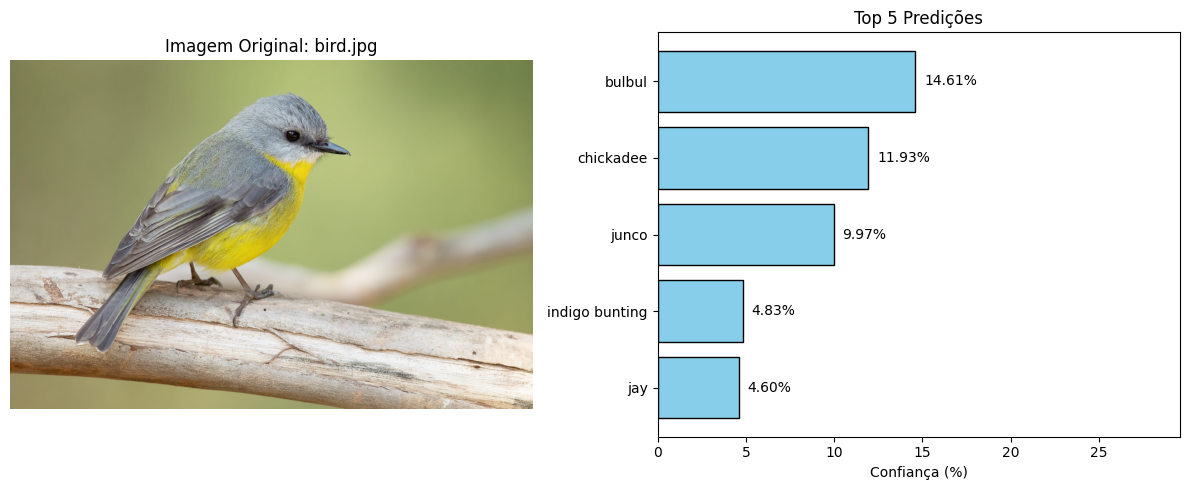

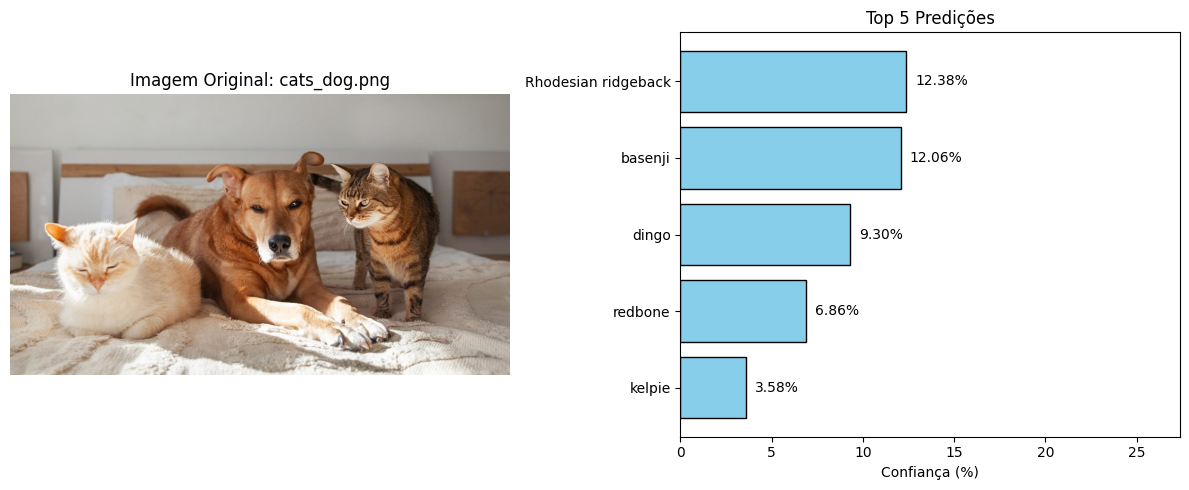

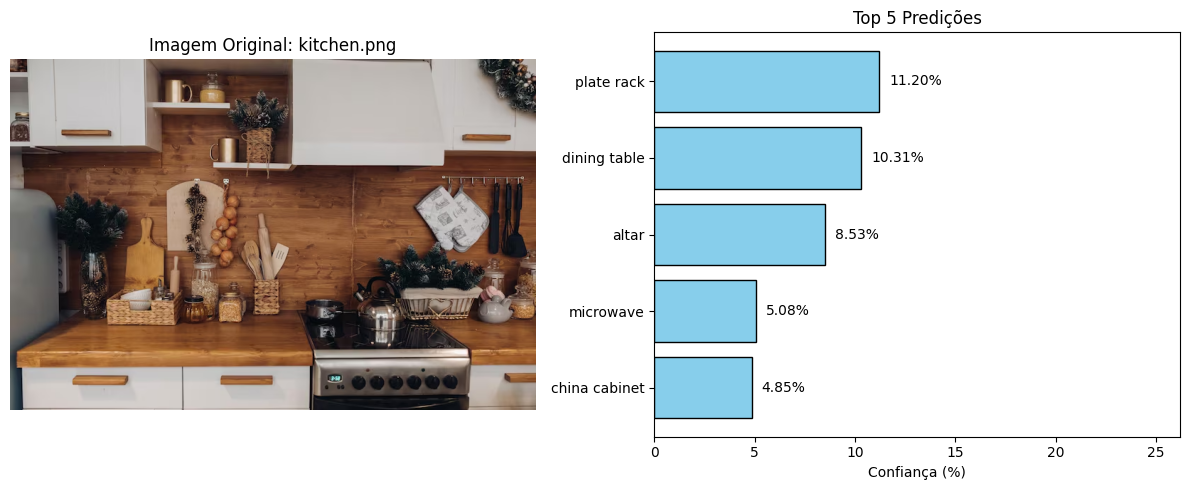

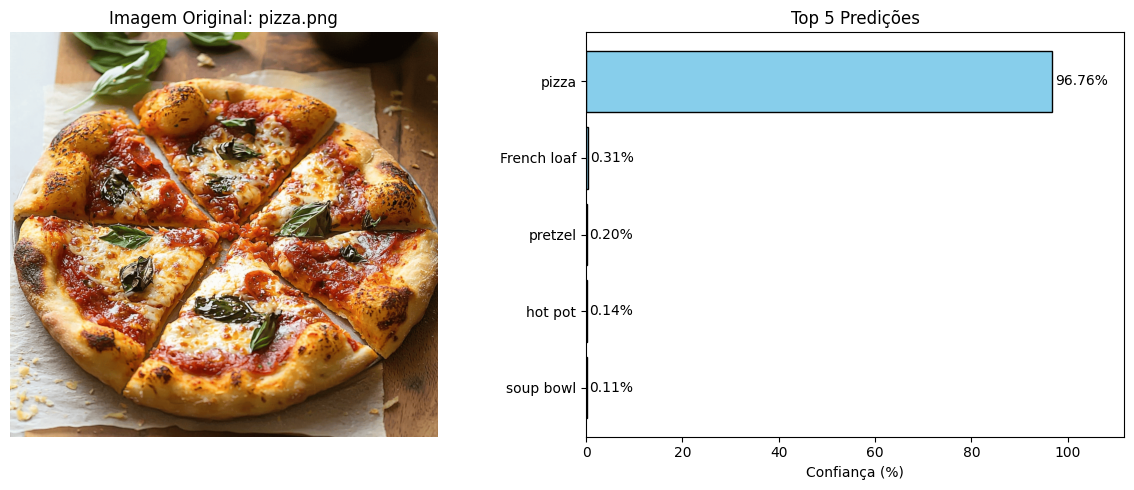

In [6]:
img_dir = Path("imagens")
imagens_paths = list(img_dir.glob("*"))

if len(imagens_paths) == 0:
    print("Nenhuma imagem localizada.")
else:
    for path in imagens_paths:
        if path.is_file():
            # Chamando a função para cada imagem encontrada
            resultado = prever_e_plotar(path, model, transform, categories)